# Marconi daily intertidal DEMs from timex waterlines (step 2)
csherwood@usgs.gov, 2026-10-23, generated with Claude Opus 5.5

Uses the inventory from `scan_imagery.ipynb` (`image_scan.csv`). For every image with quality > 1:
detect the waterline (Otsu threshold of (R − B)/(R + G + B) below the horizon; cf. the color-based
waterline mapping of Aarninkhof et al., 2003, and Plant et al., 2007), assign z = water level + setup
(Stockdon et al., 2006, with deep-water H0 by reverse shoaling), and rectify at that z with the
calibration EO/IO.

For each day, waterline points from the day before, the day of, and the day after are gridded on a 2 m UTM grid
by a weighted local plane fit. Images whose median residual to the first DEM is an outlier are dropped and
the DEM is refit. Slopes along fixed shore-normal transects give a median slope that replaces the initial 0.12 for
one iteration of the setup.

Uncertainty: σ² = se_fit² + σ_wl² + (f_setup·setup)². Here se_fit is the standard error of the local fit,
inflated for per-image correlation.

Outputs:
* `dems/dem_YYYY-MM-DD.tif` and `dems/unc_YYYY-MM-DD.tif` (GeoTIFF, EPSG:6348; elevation in the water-level datum,
  assumed NAVD88);
* `fig/dems/dem_YYYY-MM-DD.png` (fixed extent and color limits, for animation);
* `waterlines_px.csv` (waterline pixels per image), `transects.csv`, `transect_slopes.csv`, `dem_days.csv`;
* `image_scan_dem.csv` (the image inventory with per-image waterline results and the day's DEM statistics).

Requires: numpy, pandas, scipy, opencv, pyyaml, matplotlib, rasterio.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import marconi_scan as ms
import marconi_dem as md

# --- config
PROJ = Path(r'F:\crs\proj\2026_wl_dems')
CAL_DIR = Path(r'F:\crs\proj\marconi_imagery\calibration_parameters')
OUT_DIR = PROJ / 'scan'
SCAN_CSV = OUT_DIR / 'image_scan.csv'
WL_CSV = OUT_DIR / 'waterlines_px.csv'
DEM_DIR = OUT_DIR / 'dems'
FIG_DIR = PROJ / 'fig'
DEM_FIG_DIR = FIG_DIR / 'dems'
FIRST_DAY, LAST_DAY = None, None          # e.g. '2024-12-10', '2025-02-15'; None = whole scan
CFG = md.CFG | {}                         # overrides, e.g. {'radius': 6., 'zlim': (-1.5, 3.)}

for d in [DEM_DIR, DEM_FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)
scan = pd.read_csv(SCAN_CSV, parse_dates=['time'])
print(scan.groupby(['camera', 'quality']).size().unstack())

quality  -1.0    0.0    1.0    2.0     4.0
camera                                    
c1        1.0  928.0  591.0  165.0   837.0
c2        NaN  925.0  391.0   43.0  1161.0


## Waterline detection
About 0.15 s per image. Appends to `waterlines_px.csv` and resumes if rerun (delete the file to redo all).

In [2]:
info = md.detect_all(scan, CAL_DIR, WL_CSV, CFG)
wl_px = pd.read_csv(WL_CSV)
wl_g = wl_px.groupby('path')
npx = wl_px.dropna().groupby('path').size()
print(f'{len(npx)} images with a waterline; median {npx.median():.0f} px per image')

100/2206  2024-12-15 15:30:00
200/2206  2024-12-21 18:30:00
300/2206  2025-01-02 13:30:00
400/2206  2025-01-10 13:30:00
500/2206  2025-01-14 17:30:00
600/2206  2025-01-18 15:00:00
700/2206  2025-01-21 21:00:00
800/2206  2025-01-26 13:00:00
900/2206  2025-01-28 19:30:00
1000/2206  2025-01-31 16:00:00
1100/2206  2025-02-07 16:00:00
1200/2206  2025-02-10 15:30:00
1300/2206  2025-02-14 17:00:00
1400/2206  2025-02-17 18:30:00
1500/2206  2025-02-20 13:30:00
1600/2206  2025-02-22 17:30:00
1700/2206  2025-02-25 11:30:00
1800/2206  2025-02-27 17:00:00
1900/2206  2025-03-02 11:30:00
2000/2206  2025-03-04 15:30:00
2100/2206  2025-03-07 19:00:00
2200/2206  2025-03-10 13:30:00
2206/2206  2025-03-10 15:00:00
2206 images with a waterline; median 1214 px per image


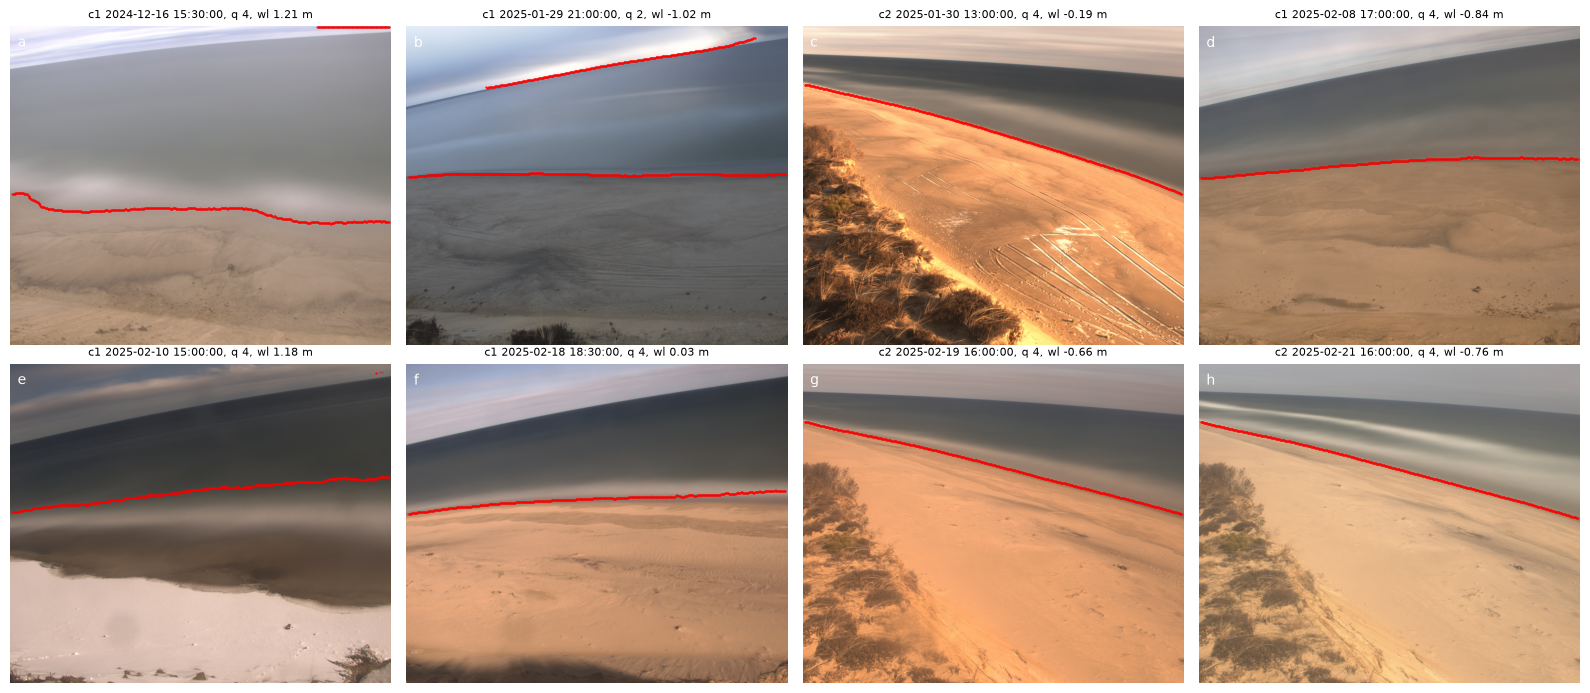

In [3]:
# waterlines on a random sample of images
ex = scan[scan.path.isin(npx.index)].sample(8, random_state=2).sort_values('time').reset_index(drop=True)
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for i, a in enumerate(ax.flat):
    p = wl_g.get_group(ex.path[i])
    a.imshow(cv2.cvtColor(cv2.imread(ex.path[i]), cv2.COLOR_BGR2RGB))
    a.plot(p.u, p.v, '.', c='r', ms=0.5)
    a.set_title(f'{ex.camera[i]} {ex.time[i]}, q {ex.quality[i]:.0f}, wl {ex.water_level[i]:.2f} m', fontsize=8)
    a.axis('off')
    a.text(0.02, 0.97, chr(97 + i), transform=a.transAxes, va='top', color='w')
fig.tight_layout()
fig.savefig(FIG_DIR / 'waterline_examples.jpg', dpi=120)

## Grid, shore frame, and transects (fixed for all days)
From all waterline points with the initial slope. The offshore direction is the minor principal axis of the
points, signed toward lower elevations.

778479 points from 2205 images; grid 157 x 188 cells; offshore azimuth 77.9 deg; 34 transects


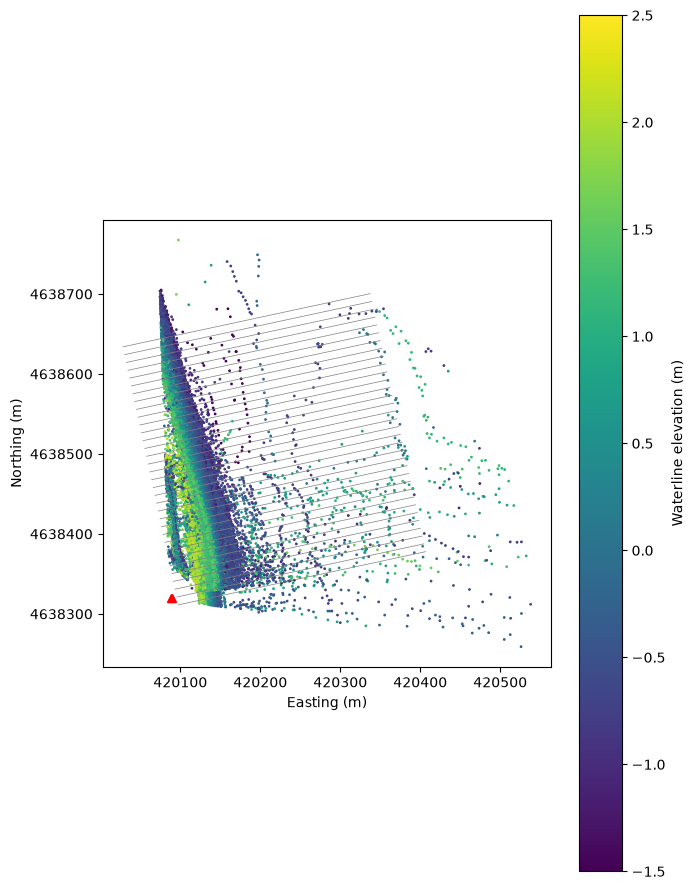

In [4]:
use = scan[scan.path.isin(npx.index) & scan.H0.notna() & scan.water_level.notna()]
p0 = md.waterline_points(use, wl_g, CAL_DIR, CFG['beta0'], CFG)
xg, yg = md.make_grid(p0.x, p0.y, CFG['dx'])
o, along, off, az_off = md.shore_frame(p0.x.values, p0.y.values, p0.z.values)
tr, trX, trY, trs = md.make_transects(p0.x.values, p0.y.values, o, along, off, CFG)
tr.to_csv(OUT_DIR / 'transects.csv', index=False, float_format='%.2f')
print(f'{len(p0)} points from {p0.img.nunique()} images; grid {len(xg)} x {len(yg)} cells; '
      f'offshore azimuth {az_off:.1f} deg; {len(tr)} transects')

fig, ax = plt.subplots(figsize=(7, 9))
sc = ax.scatter(p0.x[::20], p0.y[::20], c=p0.z[::20], s=1, cmap='viridis', vmin=CFG['zlim'][0], vmax=CFG['zlim'][1])
for _, t in tr.iterrows():
    ax.plot([t.x0, t.x1], [t.y0, t.y1], c='0.5', lw=0.5)
for cam in use.camera.unique():
    eo = ms.read_yaml(CAL_DIR / use[use.camera == cam].eo_file.iloc[0])
    ax.plot(eo['x'], eo['y'], 'r^')
plt.colorbar(sc, label='Waterline elevation (m)')
ax.set_aspect('equal'); ax.ticklabel_format(useOffset=False, style='plain')
ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)')
fig.tight_layout()
fig.savefig(FIG_DIR / 'waterline_points_transects.png', dpi=150)

## Daily DEMs
About 5 s per day.

In [5]:
t0 = pd.Timestamp(FIRST_DAY) if FIRST_DAY else scan.time.min().floor('D')
t1 = pd.Timestamp(LAST_DAY) if LAST_DAY else scan.time.max().floor('D')
days = pd.date_range(t0, t1, freq='D')
dt, it, sl = md.run_days(scan, wl_g, CAL_DIR, days, xg, yg, tr, trX, trY, trs, DEM_DIR, DEM_FIG_DIR, CFG)
dt.to_csv(OUT_DIR / 'dem_days.csv', index=False, float_format='%.4g')
sl.to_csv(OUT_DIR / 'transect_slopes.csv', index=False, float_format='%.4g')
dt

2024-12-09 ok 920 cells
2024-12-10 ok 920 cells
2024-12-11 ok 1842 cells
2024-12-12 ok 2342 cells
2024-12-13 ok 2633 cells
2024-12-14 ok 2390 cells
2024-12-15 ok 2039 cells
2024-12-16 ok 1571 cells
2024-12-17 ok 1878 cells
2024-12-18 ok 1670 cells
2024-12-19 ok 1686 cells
2024-12-20 ok 1823 cells
2024-12-21 ok 1844 cells
2024-12-22 ok 2095 cells
2024-12-23 ok 1870 cells
2024-12-24 ok 1500 cells
2024-12-25 ok 604 cells
2024-12-26 too few images 0 cells
2024-12-27 too few images 0 cells
2024-12-28 too few images 0 cells
2024-12-29 too few images 0 cells
2024-12-30 ok 638 cells
2024-12-31 ok 638 cells
2025-01-01 ok 1899 cells
2025-01-02 ok 2057 cells
2025-01-03 ok 2057 cells
2025-01-04 ok 1647 cells
2025-01-05 too few images 0 cells
2025-01-06 too few images 0 cells
2025-01-07 ok 826 cells
2025-01-08 ok 992 cells
2025-01-09 ok 1413 cells
2025-01-10 ok 1366 cells
2025-01-11 ok 1304 cells
2025-01-12 ok 1017 cells
2025-01-13 ok 947 cells
2025-01-14 ok 967 cells
2025-01-15 ok 1075 cells
2025-

,day,n_img_window,slope_median_0,beta_0,status,slope_median_1,beta_1,beta_used,n_img_used,n_img_dropped,...,dem_zmax,unc_median,unc_mean,unc_p90,slope_n,slope_median,slope_mean,slope_std,slope_p10,slope_p90
0,2024-12-09,12,0.090007,0.12,ok,0.090852,0.090007,0.090007,11,0,...,0.973593,0.129151,0.136082,0.186195,16.0,0.090852,0.089033,0.014678,0.071470,0.104868
1,2024-12-10,12,0.090007,0.12,ok,0.090852,0.090007,0.090007,11,0,...,0.973593,0.129151,0.136082,0.186195,16.0,0.090852,0.089033,0.014678,0.071470,0.104868
2,2024-12-11,23,0.070111,0.12,ok,0.068742,0.070111,0.070111,19,2,...,1.865532,0.121548,0.131066,0.159967,26.0,0.068742,0.069561,0.014178,0.054304,0.081066
3,2024-12-12,44,0.080894,0.12,ok,0.072182,0.080894,0.080894,32,12,...,1.959469,0.134203,0.147322,0.205629,26.0,0.072182,0.059774,0.035708,0.018052,0.086910
4,2024-12-13,73,0.079558,0.12,ok,0.070071,0.079558,0.079558,51,22,...,1.968221,0.128573,0.142452,0.207212,28.0,0.070071,0.057179,0.038943,0.014296,0.095846
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87,2025-03-06,81,0.097004,0.12,ok,0.093142,0.097004,0.097004,64,15,...,1.582896,0.144793,0.153094,0.202504,32.0,0.093142,0.088964,0.023172,0.056026,0.108858
88,2025-03-07,76,0.066952,0.12,ok,0.059590,0.066952,0.066952,72,4,...,1.770513,0.115108,0.122047,0.147136,33.0,0.059590,0.054223,0.015842,0.030242,0.069919
89,2025-03-08,119,0.069800,0.12,ok,0.062542,0.069800,0.069800,107,12,...,1.483321,0.102670,0.110669,0.134153,33.0,0.062542,0.058541,0.016099,0.031552,0.074620
90,2025-03-09,98,0.070357,0.12,ok,0.072399,0.070357,0.070357,84,14,...,1.526704,0.089435,0.098614,0.129618,33.0,0.072399,0.063381,0.018694,0.034889,0.082547


## Inventory with waterline and DEM results
Per image (for its own day's DEM): `wl_npx` waterline pixels, `setup_dem` setup with that day's slope, `z_wl` assigned
elevation, `wl_resid0` median residual to the first DEM, `wl_resid` to the final DEM, `wl_used` passed the check.
Per day (repeated for each image of that day): DEM status, images used/dropped, mapped cells and area, elevation
range, uncertainty median/mean/p90, transect slope n/median/mean/std/p10/p90, and the slope used for the setup.

In [6]:
img = it.drop(columns=['path', 'day']).rename(columns={'median': 'wl_resid0', 'count': 'wl_npts', 'used': 'wl_used',
                                                       'resid': 'wl_resid'})
inv = scan.join(img).assign(wl_npx=scan.path.map(npx))
inv['z_wl'] = inv.water_level + inv.setup_dem
inv['day'] = inv.time.dt.floor('D').dt.date
day_cols = ['day', 'status', 'n_img_window', 'n_img_used', 'n_img_dropped', 'beta_used', 'dem_n_cells', 'dem_area_m2',
            'dem_zmin', 'dem_zmax', 'unc_median', 'unc_mean', 'unc_p90', 'slope_n', 'slope_median', 'slope_mean',
            'slope_std', 'slope_p10', 'slope_p90']
inv = inv.merge(dt.reindex(columns=day_cols).add_prefix('day_').rename(columns={'day_day': 'day'}), on='day', how='left')
inv.to_csv(OUT_DIR / 'image_scan_dem.csv', index=False, float_format='%.4g')
inv[inv.quality > 1].head()

,time,quality,wh_4061,wp_peak,R2,path,station,camera,wvdir,water_level,...,day_dem_zmax,day_unc_median,day_unc_mean,day_unc_p90,day_slope_n,day_slope_median,day_slope_mean,day_slope_std,day_slope_p10,day_slope_p90
1,2024-12-09 18:00:00,4.0,0.6428,5.362,0.5774,F:\crs\proj\marconi_imagery\caco-03\c2\2024\34...,CACO03,c2,56.0,-0.5299,...,0.973593,0.129151,0.136082,0.186195,16.0,0.090852,0.089033,0.014678,0.07147,0.104868
3,2024-12-09 18:30:00,4.0,0.6459,5.362,0.5787,F:\crs\proj\marconi_imagery\caco-03\c2\2024\34...,CACO03,c2,57.0,-0.3156,...,0.973593,0.129151,0.136082,0.186195,16.0,0.090852,0.089033,0.014678,0.07147,0.104868
5,2024-12-09 19:00:00,4.0,0.6490,5.362,0.5799,F:\crs\proj\marconi_imagery\caco-03\c2\2024\34...,CACO03,c2,58.0,-0.1012,...,0.973593,0.129151,0.136082,0.186195,16.0,0.090852,0.089033,0.014678,0.07147,0.104868
7,2024-12-09 19:30:00,4.0,0.6718,5.255,0.5774,F:\crs\proj\marconi_imagery\caco-03\c2\2024\34...,CACO03,c2,55.0,0.1528,...,0.973593,0.129151,0.136082,0.186195,16.0,0.090852,0.089033,0.014678,0.07147,0.104868
9,2024-12-09 20:00:00,4.0,0.6946,5.148,0.5744,F:\crs\proj\marconi_imagery\caco-03\c2\2024\34...,CACO03,c2,52.0,0.4068,...,0.973593,0.129151,0.136082,0.186195,16.0,0.090852,0.089033,0.014678,0.07147,0.104868


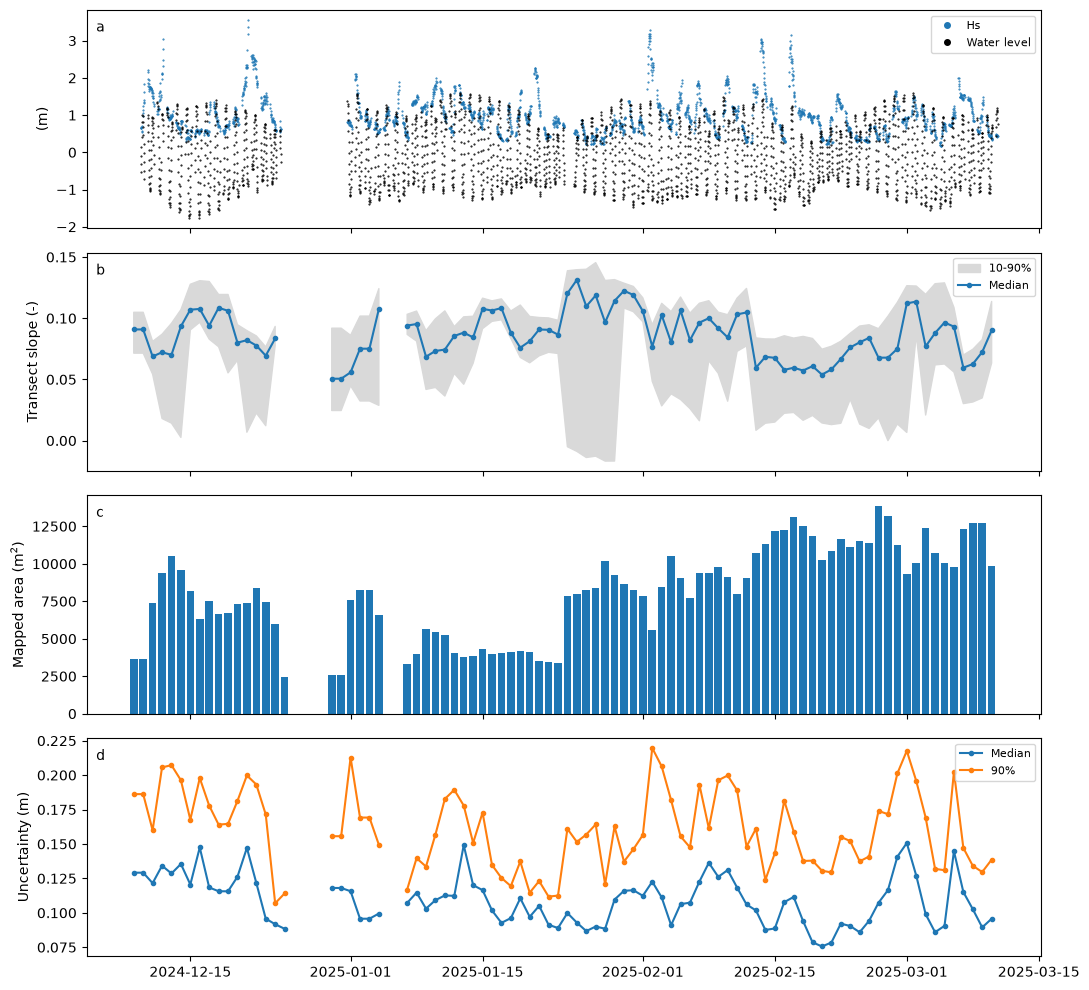

In [7]:
d = dt.assign(day=pd.to_datetime(dt.day))
fig, ax = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
w = scan.drop_duplicates('time')
ax[0].plot(w.time, w.wh_4061, '.', ms=1, c='tab:blue', label='Hs')
ax[0].plot(w.time, w.water_level, '.', ms=1, c='k', label='Water level')
ax[0].set_ylabel('(m)'); ax[0].legend(fontsize=8, markerscale=8)
ax[1].fill_between(d.day, d.slope_p10, d.slope_p90, color='0.85', label='10-90%')
ax[1].plot(d.day, d.slope_median, 'o-', ms=3, label='Median')
ax[1].set_ylabel('Transect slope (-)'); ax[1].legend(fontsize=8)
ax[2].bar(d.day, d.dem_area_m2, width=0.8)
ax[2].set_ylabel('Mapped area (m$^2$)')
ax[3].plot(d.day, d.unc_median, 'o-', ms=3, label='Median')
ax[3].plot(d.day, d.unc_p90, 'o-', ms=3, label='90%')
ax[3].set_ylabel('Uncertainty (m)'); ax[3].legend(fontsize=8)
for a, l in zip(ax, 'abcd'):
    a.text(0.01, 0.95, l, transform=a.transAxes, va='top')
fig.tight_layout()
fig.savefig(FIG_DIR / 'dem_daily_stats.png', dpi=150)